In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

In [2]:
# Car speed (km/h) vs braking distance (m) - distance grows roughly with speed squared
X = np.array([20, 30, 40, 50, 60, 70, 80, 90, 100, 110]).reshape(-1, 1)
y = np.array([5.1, 9.8, 16.2, 24.5, 34.9, 47.3, 62.4, 78.9, 98.2, 118.6])

In [3]:
model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06


In [4]:
prediction = model.predict([[120]])
print("Predicted braking distance at 120 km/h (m):", round(prediction[0], 2))

Predicted braking distance at 120 km/h (m): 141.72


In [5]:
y_pred = model.predict(X)
print("R2 Score:", round(r2_score(y, y_pred), 4))
print("Mean Absolute Error:", round(mean_absolute_error(y, y_pred), 4))

lin = model.named_steps["linearregression"]
print("Coefficients:", np.round(lin.coef_, 4))
print("Intercept:", round(lin.intercept_, 4))

R2 Score: 1.0
Mean Absolute Error: 0.1764
Coefficients: [ 0.     -0.0867  0.0104]
Intercept: 2.8909


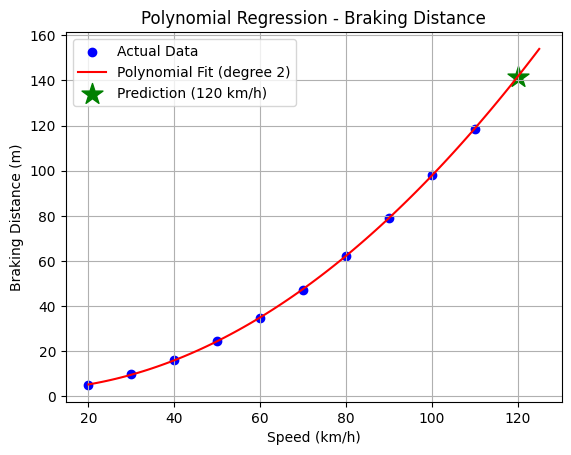

In [6]:
X_line = np.linspace(20, 125, 100).reshape(-1, 1)

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_line, model.predict(X_line), color="red", label="Polynomial Fit (degree 2)")
plt.scatter(120, prediction[0], color="green", marker="*", s=250, label="Prediction (120 km/h)")

plt.xlabel("Speed (km/h)")
plt.ylabel("Braking Distance (m)")
plt.title("Polynomial Regression - Braking Distance")
plt.legend()
plt.grid(True)
plt.show()